# Lecture : Graph Transformers 

## Lab 03 : Graph Transformers with edge features and PyG (sparse linear algebra) -- Solution

### Xavier Bresson, Guoji Fu, Ryoji Kubo

Dwivedi, Bresson, A generalization of transformer networks to graphs, 2020   
https://arxiv.org/pdf/2012.09699.pdf

This notebook is the [PyTorch Geometric (PyG)](https://pytorch-geometric.readthedocs.io) mirror of the original DGL
notebook. The molecules are loaded directly as PyG `Data` objects (no DGL), and the graph multi-head attention is
implemented from scratch with PyG's `MessagePassing` class -- no pre-built attention layer such as
`torch_geometric.nn.TransformerConv` is used.

In [1]:
# For Google Colaboratory
import sys, os
if 'google.colab' in sys.modules:
    # mount google drive
    from google.colab import drive
    drive.mount('/content/gdrive')
    path_to_file = '/content/gdrive/My Drive/CS5284_2026_codes/07_Graph_Transformers'
    print(path_to_file)
    # change current path to the folder containing "path_to_file"
    os.chdir(path_to_file)
    !pwd
    !pip -q install torch_geometric==2.5.1 # Install PyG (same version as the course environment)


In [2]:
# Libraries
import pickle
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import Tensor
import torch.nn as nn
import time
import networkx as nx
import sys; sys.path.insert(0, 'lib/')
import ncut # spectral clustering (normalized cut), used to color the nodes in the visualization
import os, datetime

# PyTorch Geometric
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import MessagePassing, global_mean_pool
from torch_geometric.utils import degree, softmax, to_dense_adj

_ = torch.manual_seed(0)

# Load molecular datasets

The molecules are stored in `dataset/QM9_1.4k_pytorch/` as pickled `Molecule` objects (the full class is in
`lib/molecules.py`): the atom types, a dense $N\times N$ matrix of bond types, and the chemical target. The DGL
graphs used by the original notebook (`dataset/QM9_1.4k_dgl/`) were built from these same files, so converting
them directly gives exactly the same graphs, in the same order.

A PyG graph is a `Data` object holding plain tensors:
  - `data.x` of size `(num_nodes,)`: the atom types (integers, fed to an `nn.Embedding`),
  - `data.edge_index` of size `(2, num_edges)`: `edge_index[0]` = source nodes $j$, `edge_index[1]` = destination
    nodes $i$ (PyG's default message flow is `source_to_target`, i.e. $j \rightarrow i$),
  - `data.edge_attr` of size `(num_edges,)`: the bond types (integers, fed to an `nn.Embedding`),
  - `data.y` of size `(1,1)`: the chemical property to regress.

Every chemical bond is stored in both directions, since the bond-type matrix is symmetric.

In [3]:
# The molecules were pickled from a notebook, so pickle looks up the classes `Dictionary` and `Molecule`
# in this notebook. Pickle only restores the attributes of the objects, so lightweight containers are
# enough here (lib/molecules.py holds the full classes, but it cannot be imported without DGL).
class Dictionary:
    '''Atom or bond vocabulary: idx2word (list of names) and word2idx (dict name -> index).'''
    def __len__(self):
        return len(self.idx2word)

class Molecule:
    '''
    num_atom : nb of atoms N
    atom_type : (N,) atom type of every atom, integer in [0, num_atom_type-1]
    bond_type : (N,N) bond type between every pair of atoms, integer in [0, num_bond_type-1], 0 = no bond
    logP_SA_cycle_normalized : (1,) the chemical property to regress
    smile : the SMILES string of the molecule
    '''


# Convert a molecule into a PyG Data object
def molecule_to_pyg(molecule):
    adj = molecule.bond_type # (N,N) bond types, 0 = no bond
    edge_index = (adj != 0).nonzero().t().contiguous() # converting adj matrix to edge_list, size=(2,num_edges)
    edge_attr = adj[edge_index[0], edge_index[1]].long() # bond type of every edge, size=(num_edges,)
    x = molecule.atom_type.long() # atom type of every node, size=(num_nodes,)
    y = molecule.logP_SA_cycle_normalized.view(1, 1) # chemical target, size=(1,1)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y, num_nodes=molecule.num_atom)


# Select dataset
dataset_name = 'QM9_1.4k'; data_folder_pytorch = 'dataset/QM9_1.4k_pytorch/'

# Load the number of atom and bond types
with open(data_folder_pytorch + "atom_dict.pkl" ,"rb") as f: num_atom_type = len(pickle.load(f))
with open(data_folder_pytorch + "bond_dict.pkl" ,"rb") as f: num_bond_type = len(pickle.load(f))
print(num_atom_type)
print(num_bond_type)

# Load the molecules and convert them into PyG graphs
def load_molecules(split):
    with open(data_folder_pytorch + "%s_pytorch.pkl" % split, "rb") as f:
        molecules = pickle.load(f)
    return [ molecule_to_pyg(molecule) for molecule in molecules ]

trainset = load_molecules('train')
valset = load_molecules('val')
testset = load_molecules('test')
print(len(trainset))
print(len(valset))
print(len(testset))
idx = 0
print(trainset[:2])
print(valset[idx])
print(testset[idx])

9
4
1000
200
200
[Data(x=[9], edge_index=[2, 20], edge_attr=[20], y=[1, 1], num_nodes=9), Data(x=[9], edge_index=[2, 18], edge_attr=[18], y=[1, 1], num_nodes=9)]
Data(x=[9], edge_index=[2, 18], edge_attr=[18], y=[1, 1], num_nodes=9)
Data(x=[9], edge_index=[2, 20], edge_attr=[20], y=[1, 1], num_nodes=9)


# Add positional encoding feature

PyG has no `g.adj()` or `g.in_degrees()` methods attached to the graph: the dense adjacency matrix is built from
`edge_index` with [`to_dense_adj()`](https://pytorch-geometric.readthedocs.io/en/latest/modules/utils.html#torch_geometric.utils.to_dense_adj)
and the in-degrees with [`degree()`](https://pytorch-geometric.readthedocs.io/en/latest/modules/utils.html#torch_geometric.utils.degree).
The positional encoding is stored in a new attribute `graph.pos_enc` of size `(num_nodes, pos_enc_dim)`, which PyG
concatenates along the node dimension when it batches graphs.

In [4]:
# Positional encoding as Laplacian eigenvectors
def LapEig_positional_encoding(graph, pos_enc_dim):
    num_nodes = graph.num_nodes
    Adj = to_dense_adj(graph.edge_index, max_num_nodes=num_nodes)[0] # Adjacency matrix
    Dn = ( degree(graph.edge_index[1], num_nodes=num_nodes)** -0.5 ).diag() # Inverse and sqrt of degree matrix
    Lap = torch.eye(num_nodes) - Dn.matmul(Adj).matmul(Dn) # Laplacian operator
    EigVal, EigVec = torch.linalg.eig(Lap) # Compute full EVD
    EigVal, EigVec = EigVal.real, EigVec.real # make eig real
    EigVec = EigVec[:, EigVal.argsort()] # sort in increasing order of eigenvalues
    EigVec = EigVec[:,1:pos_enc_dim+1] # select the first non-trivial "pos_enc_dim" eigenvector
    return EigVec

# Add node positional encoding features to graphs
pos_enc_dim = 3 # dimension of PE, QM9
def add_node_edge_features(dataset):
    for graph in dataset:
        graph.pos_enc = LapEig_positional_encoding(graph, pos_enc_dim) # node positional encoding feature
    return dataset

# Generate graph datasets
trainset = add_node_edge_features(trainset)
testset = add_node_edge_features(testset)
valset = add_node_edge_features(valset)
print(trainset[0])

Data(x=[9], edge_index=[2, 20], edge_attr=[20], y=[1, 1], num_nodes=9, pos_enc=[9, 3])


# Visualize positional encoding

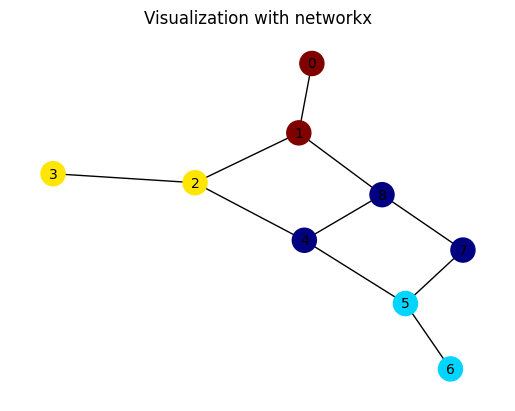

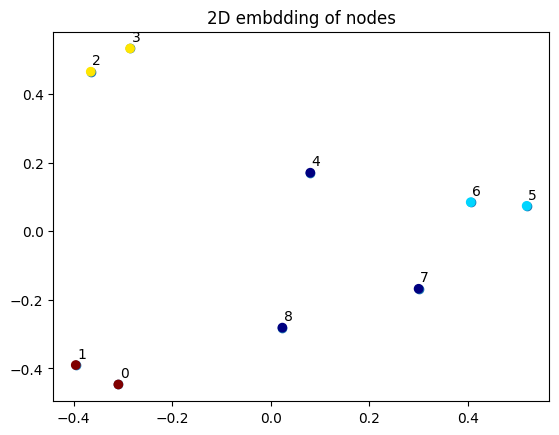

In [5]:
# Spectral clustering of a graph into R clusters, used to color the nodes
# (same function as lib/utils.compute_ncut, which cannot be imported here because lib/utils imports DGL)
def compute_ncut(Adj, R):
    eigen_val, eigen_vec = ncut.ncut( Adj.numpy(), R ) # Apply ncut
    eigenvec_discrete = ncut.discretisation( eigen_vec ) # Discretize to get cluster id
    res = eigenvec_discrete.dot(np.arange(1, R + 1))
    C = torch.tensor(res-1).long()
    return C

graph = trainset[0]

# Visualize graph
fig = plt.figure()
ax = fig.add_subplot(111)
Adj = to_dense_adj(graph.edge_index, max_num_nodes=graph.num_nodes)[0]
A_nx = nx.from_numpy_array(Adj.numpy())
C = compute_ncut(Adj.long(), 4)
nx.draw(A_nx, ax=ax, node_color=C, cmap='jet', with_labels=True, font_size=10) # visualise node indexes
ax.title.set_text('Visualization with networkx')
plt.show()

# plot 2D coordinates
fig = plt.figure()
ax = fig.add_subplot(111)
x = graph.pos_enc
ax.scatter(x[:,0], x[:,1])
idx = list(range(graph.num_nodes))
ax.scatter(x[:,0], x[:,1], c=C, cmap='jet')
for i, txt in enumerate(idx):
    ax.annotate(txt, (x[:,0][i], x[:,1][i]), textcoords="offset points", xytext=(1,5))
ax.title.set_text('2D embdding of nodes')
plt.show()

# Use the PyG DataLoader to prepare a batch of graphs and test it

As in DGL, batching builds a **block-diagonal** adjacency matrix: node features (`x`, `pos_enc`), edge features
(`edge_attr`) and labels (`y`) are concatenated, and the node indices stored in `edge_index` are shifted by the
cumulated number of nodes of the previous graphs. The batched graph additionally carries a vector `batch` of size
`(num_nodes_of_the_batch,)` that maps every node to the index of the graph it belongs to -- this is what the
graph-level readout uses.

In [6]:
# PyG concatenates the graphs, offsets edge indices, and creates a `batch`
# vector that maps every node to its graph in the mini-batch.
batch_size = 10
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
batch_graphs = next(iter(train_loader))
batch_labels = batch_graphs.y
print(batch_graphs)
print(batch_labels)
batch_x = batch_graphs.x
print('batch_x:',batch_x.size())
batch_pe = batch_graphs.pos_enc
print('batch_pe:',batch_pe.size())
batch_e = batch_graphs.edge_attr
print('batch_e:',batch_e.size())
print('batch vector:',batch_graphs.batch.size())

DataBatch(x=[88], edge_index=[2, 194], edge_attr=[194], y=[10, 1], num_nodes=88, pos_enc=[88, 3], batch=[88], ptr=[11])
tensor([[-3.0030],
        [ 0.2559],
        [-0.9657],
        [-0.0640],
        [ 0.3006],
        [ 0.4742],
        [ 0.8561],
        [ 2.1134],
        [ 0.1270],
        [-0.3182]])
batch_x: torch.Size([88])
batch_pe: torch.Size([88, 3])
batch_e: torch.Size([194])
batch vector: torch.Size([88])


# Exercise 1: Design the class of GraphTransformer networks with edge features

Node update equation:  
\begin{align}
\bar{h}^{\ell} &=&  h^{\ell} + \textrm{gMHA} (\textrm{LN}(h^{\ell}),\textrm{LN}(e^{\ell})) \in \mathbb{R}^{N\times d}\\
h^{\ell+1} &=& \bar{h}^{\ell} + \textrm{MLP} (\textrm{LN}(\bar{h}^{\ell}))  \in \mathbb{R}^{N\times d}\\
&&\textrm{with } \textrm{gMHA}(h,e)=\textrm{Concat}_{k=1}^H \left( \textrm{gHA}(h_k,e_k) \right) W_O \in \mathbb{R}^{N\times d},\ h_k\in \mathbb{R}^{N\times d'=d/H}, e_k\in \mathbb{R}^{E\times d'}, W_O\in \mathbb{R}^{d\times d} \\
&&\quad\quad\ \textrm{gHA}(h,e)_i= \sum_{j\in \mathcal{N}_i} \underbrace{\frac{\exp(q_i^T \textrm{diag}(e_{ij}) k_j/\sqrt{d'})}{ \sum_{j'\in\mathcal{N}_i} \exp(q_i^T \textrm{diag}(e_{ij'}) k_{j'}/\sqrt{d'}) }}_{\textrm{graph attention score w/ edge feature}_{ij}} v_j\ \textrm{ (point-wise equation)}\\
&&\quad\quad\ Q=h_k W_Q, K=h_k W_K, V=h_k W_V\in \mathbb{R}^{N\times d'=d/H}, E=e_k W_E\in \mathbb{R}^{E\times d'=d/H}, W_Q, W_K, W_V, W_E\in \mathbb{R}^{d'\times d'}\\
h^{\ell=0} &=& \textrm{LL}_1(h_0)+\textrm{LL}_2(p_0) \in \mathbb{R}^{N\times d}\ \textrm{(input node feature and positional encoding)}\\
&&\textrm{with } p_0=\Phi_{\{2,..,K+1\}}\in \mathbb{R}^{N\times K},\ \Delta = \Phi \Lambda \Phi^T \in \mathbb{R}^{N\times N}
\end{align}

Edge update equation:  
\begin{align}
\bar{e}^{\ell} &=&  e^{\ell} + \textrm{gMHE} (\textrm{LN}(e^{\ell}),\textrm{LN}(h^{\ell}))  \in \mathbb{R}^{E\times d}\\
e^{\ell+1} &=& \bar{e}^{\ell} + \textrm{MLP} (\textrm{LN}(\bar{e}^{\ell})) \in \mathbb{R}^{E\times d}\\
&&\textrm{with } \textrm{gMHE}(e,h)=\textrm{Concat}_{k=1}^H \left( \textrm{gHE}(e_k,h_k) \right) W_O^e \in \mathbb{R}^{E\times d},\ h_k\in \mathbb{R}^{N\times d'=d/H}, e_k\in \mathbb{R}^{E\times d'}, W_O^e\in \mathbb{R}^{d\times d} \\
&&\textrm{with } \textrm{gHE}(e,h)_{ij}=q_i \odot e_{ij} \odot k_j/\sqrt{d'} \in \mathbb{R}^{d'} \textrm{ (point-wise equation)}\\
e^{\ell=0} &=& \textrm{LL}(e_0) \in \mathbb{R}^{E\times d}\ \textrm{(input edge feature)}\\
\end{align}


### Question 1.1: Implement a Graph Multi-Head Attention (MHA) Layer with edge features

PyG implements message-passing with the class
[`MessagePassing`](https://pytorch-geometric.readthedocs.io/en/latest/modules/nn.html#torch_geometric.nn.MessagePassing),
whose two entry points are the counterparts of DGL's `message_func()` / `reduce_func()`:

  - `self.edge_updater(edge_index, ...)` calls `edge_update()` and returns **one feature per edge**. This is where the
    new edge feature is computed -- in DGL this was done as a side effect inside `message_func()` with
    `edges.data['e'] = eij`.
  - `self.propagate(edge_index, ...)` calls `message()`, sums the messages on every destination node $i$ (constructor
    argument `aggr='add'`), and passes the result to `update()`.

Any tensor `xx` given to `edge_updater()`/`propagate()` is read inside `edge_update()`/`message()` as `xx_i` (feature
of the **destination** node $i$, i.e. DGL's `edges.dst['xx']`), as `xx_j` (feature of the **source** node $j$, i.e.
`edges.src['xx']`), or as `xx` when it already lives on the edges (i.e. `edges.data['xx']`). PyG performs the lifting
automatically: `xx_j` is nothing but `xx[edge_index[0]]`.

**Instructions:**

- *Step 1 of message-passing with PyG:* Pass node feature and edge features along edges (src/j => dst/i) by:
    - *Step 1.1:* In `message()`, compute bi-linear products with edge feature: $q_i^T * diag(e_{ij}) * k_j$. You may use ```Q_i``` for ```i```, ```K_j``` for ```j```, ```E``` for ```ij```.  

    - *Step 1.2:* In `message()`, compute $\textrm{exp}_{ij} = \exp( q_i^T * diag(e_{ij}) * k_j / \sqrt{d'} )$, ```size=(E,K,1)```.

    - *Step 1.3:* In `message()`, obtain ```V_j```.

    - *Step 1.4:* In `edge_update()`, compute edge feature: $q_i \odot e_{ij} \odot k_j / \sqrt{d'}$, ```size=(E,K,d')```.

    - *Step 1.5:* In `forward()`, update edge feature with ```self.edge_updater()```.

- *Step 2 of message-passing with PyG:* `aggr='add'` sums the messages sent to node dst/i, and `update()` receives the sums:
    - *Step 2.1:* DGL's `reduce_func()` could compute two separate sums over the neighbors because it materializes a
      mailbox; PyG sums with a single scatter operation. So `message()` sends the two terms
      $\{\textrm{exp}_{ij}\, v_j, \textrm{exp}_{ij}\}$ concatenated along the feature dimension, ```size=(E,K,d'+1)```.
    
    - *Step 2.2:* In `update()`, split the sums over the graph neighbors ```j``` in ```Ni``` into the numerator
      $\sum_j \textrm{exp}_{ij}\, v_j$ and the denominator $\sum_{j'} \textrm{exp}_{ij'}$, and divide them.

- Reshape ```Q, K, V, E``` with ```.view(-1, num_heads, head_hidden_dim)``` and give them to ```self.edge_updater()``` and
  ```self.propagate()```. Because these tensors have size ```(N,K,d')```, the layer is built with ```node_dim=0```: PyG's
  default ```node_dim=-2``` would treat the head dimension ```K``` as the node dimension.

Note on `propagate_type` / `edge_updater_type`: PyG compiles a specialized `propagate()` and `edge_updater()` for every
layer class, and it usually infers the names/types of their arguments by *parsing the source code* of the class. This
parsing is not always available for a class defined in a notebook cell, so the two class attributes declare them
explicitly.

In [7]:
# class graph multi head attention layer
class graph_MHA_layer(MessagePassing): # MHA = Multi Head Attention

    # Declare the type of the tensors given to edge_updater() and propagate(), see the note above
    edge_updater_type = {'Q': Tensor, 'K': Tensor, 'E': Tensor}
    propagate_type = {'Q': Tensor, 'K': Tensor, 'V': Tensor, 'E': Tensor}

    def __init__(self, hidden_dim, head_hidden_dim, num_heads): # hidden_dim = d
        # aggr='add' : the messages arriving at node i are summed  => sum_{j in Ni}
        # flow='source_to_target' : edge_index[0]=j is the source, edge_index[1]=i is the destination
        # node_dim=0 : the node dimension of the tensors of size (N,K,d') is dimension 0
        super().__init__(aggr='add', flow='source_to_target', node_dim=0)
        self.head_hidden_dim = head_hidden_dim # head_hidden_dim = d' = d/K
        self.num_heads = num_heads # number of heads = K
        self.WQ = nn.Linear(hidden_dim, head_hidden_dim * num_heads, bias=True) # define K x W matrix of size=(d',d')
        self.WK = nn.Linear(hidden_dim, head_hidden_dim * num_heads, bias=True)
        self.WV = nn.Linear(hidden_dim, head_hidden_dim * num_heads, bias=True)
        self.WE = nn.Linear(hidden_dim, head_hidden_dim * num_heads, bias=True)

    # Step 1 of message-passing with PyG:
    #   edge_update() computes one feature per edge (src/j => dst/i), called by self.edge_updater()
    def edge_update(self, Q_i, K_j, E):
        ###############################################
        # YOUR CODE STARTS
        ###############################################
        # Step 1.4: Compute edge feature: e_ij = q_i * diag(E_ij) * k_j / sqrt(d'), size=(E,K,d'), Q_i/K_j/E.size=(E,K,d')
        eij = K_j * E * Q_i / torch.sqrt(torch.tensor(self.head_hidden_dim))
        ###############################################
        # YOUR CODE ENDS
        ###############################################
        return eij # return the updated edge feature

    # Step 1 of message-passing with PyG:
    #   message() builds the message sent by node src/j to node dst/i
    def message(self, Q_i, K_j, V_j, E):
        ###############################################
        # YOUR CODE STARTS
        ###############################################
        # Step 1.1: Compute bi-linear products with edge feature
        qikj = (K_j * E * Q_i).sum(dim=2).unsqueeze(2) # size=(E,K,1), Q_i/K_j/E.size=(E,K,d')

        # Step 1.2: Compute exp_ij = exp( q_i^T * diag(E_ij) * k_j / sqrt(d') ), size=(E,K,1)
        expij = torch.exp( qikj / torch.sqrt(torch.tensor(self.head_hidden_dim)) )

        # Step 1.3: Obtain vj
        vj = V_j # size=(E,K,d')

        # Step 2.1: Send the two terms {exp_ij . v_j, exp_ij} to node dst/i, size=(E,K,d'+1)
        msg = torch.cat([expij * vj, expij], dim=2)
        ###############################################
        # YOUR CODE ENDS
        ###############################################
        return msg

    # Step 2 of message-passing with PyG:
    #   aggr='add' sums all messages sent to node dst/i, and update() receives these sums
    def update(self, aggr_out):
        ###############################################
        # YOUR CODE STARTS
        ###############################################
        # Step 2.2: Split the sums over the graph neigbors j in Ni
        # sum_j exp_ij . v_j, size=(N,K,d')
        numerator = aggr_out[:, :, :-1]

        # sum_j' exp_ij', size=(N,K,1)
        denominator = aggr_out[:, :, -1:]

        # h_i = sum_j score_ij . v_j , where score_ij = exp_ij / sum_j' exp_ij', size=(N,K,d')
        h = numerator / denominator
        ###############################################
        # YOUR CODE ENDS
        ###############################################
        return h

    def forward(self, h, e, edge_index):
        Q = self.WQ(h) # size=(N, d)
                       # computational trick to compute quickly K linear transformations h_k.WQ of size=(N, d')
                       # first compute linear transformation h.WQ of size=(N, d)
                       # then reshape h.WQ of size=(N, K, d'=d/K)
        K = self.WK(h) # size=(N, d)
        V = self.WV(h) # size=(N, d)
        E = self.WE(e) # size=(E, d)

        ###############################################
        # YOUR CODE STARTS
        ###############################################
        Q = Q.view(-1, self.num_heads, self.head_hidden_dim) # size=(N, K, d'=d/K)
        K = K.view(-1, self.num_heads, self.head_hidden_dim) # size=(N, K, d'=d/K)
        V = V.view(-1, self.num_heads, self.head_hidden_dim) # size=(N, K, d'=d/K)
        E = E.view(-1, self.num_heads, self.head_hidden_dim) # size=(E, K, d'=d/K)
        gMHE = self.edge_updater(edge_index, Q=Q, K=K, E=E) # Step 1.5: update edge feature with PyG, size=(E, K, d'=d/K)
        gMHA = self.propagate(edge_index, Q=Q, K=K, V=V, E=E, size=(h.size(0), h.size(0))) # compute with PyG the graph MHA, size=(N, K, d'=d/K)
        ###############################################
        # YOUR CODE ENDS
        ###############################################

        return gMHA, gMHE




### What do `edge_updater()` and `propagate()` actually do?

They are *not* black boxes: they lift the node tensors to the edges (`Q[dst]`, `K[src]`, `V[src]`), call
`edge_update()` / `message()`, and scatter the messages back to the destination nodes. The cell below re-implements
the graph MHA layer with plain PyTorch indexing and `index_add_` for the sums over the neighbors, and checks that it
returns the same node and edge features.

It also shows that the attention scores $\textrm{exp}_{ij} / \sum_{j'} \textrm{exp}_{ij'}$ are a softmax over the
neighbors $j$ of each node $i$, which PyG provides as
[`torch_geometric.utils.softmax(src, index)`](https://pytorch-geometric.readthedocs.io/en/latest/modules/utils.html#torch_geometric.utils.softmax),
where `index` gives the destination node $i$ of every edge.

In [8]:
# Graph MHA layer with edge features written without MessagePassing
def graph_MHA_from_scratch(layer, h, e, edge_index):
    src, dst = edge_index[0], edge_index[1] # src = j, dst = i
    N, K, d = h.size(0), layer.num_heads, layer.head_hidden_dim
    Q = layer.WQ(h).view(-1, K, d)
    Kk = layer.WK(h).view(-1, K, d)
    V = layer.WV(h).view(-1, K, d)
    E = layer.WE(e).view(-1, K, d)
    sqrt_d = torch.sqrt(torch.tensor(d))

    eij = Kk[src] * E * Q[dst] / sqrt_d # edge_update() : "_i"/"_j" lifting = indexing with dst/src
    expij = torch.exp( (Kk[src] * E * Q[dst]).sum(dim=2, keepdim=True) / sqrt_d ) # message()
    numerator = torch.zeros(N, K, d).index_add_(0, dst, expij * V[src]) # aggr='add' : sum over j in Ni
    denominator = torch.zeros(N, K, 1).index_add_(0, dst, expij)
    h_out = numerator / denominator # update()

    # same attention with PyG's softmax over the neighbors of each destination node
    scoreij = softmax( (Kk[src] * E * Q[dst]).sum(dim=2, keepdim=True) / sqrt_d, index=dst, num_nodes=N ) # size=(E,K,1)
    h_softmax = torch.zeros(N, K, d).index_add_(0, dst, scoreij * V[src])
    return h_out, eij, h_softmax

with torch.no_grad():
    layer = graph_MHA_layer(128, 128//8, 8)
    h = torch.randn(batch_graphs.num_nodes, 128)
    e = torch.randn(batch_graphs.num_edges, 128)
    gMHA, gMHE = layer(h, e, batch_graphs.edge_index)
    h_scratch, e_scratch, h_softmax = graph_MHA_from_scratch(layer, h, e, batch_graphs.edge_index)
    print('max |gMHA - from scratch|     =', (gMHA - h_scratch).abs().max().item())
    print('max |gMHE - from scratch|     =', (gMHE - e_scratch).abs().max().item())
    print('max |gMHA - with softmax()|   =', (gMHA - h_softmax).abs().max().item())

max |gMHA - from scratch|     = 0.0
max |gMHE - from scratch|     = 0.0
max |gMHA - with softmax()|   = 2.384185791015625e-07


### Question 1.2: Implement a Graph Transformer layer (with edge feature)

- Implement dropout, layer normalization, and residual connection layers for edge features.

In [9]:
# class GraphTransformer layer
class GraphTransformer_layer(nn.Module):

    def __init__(self, hidden_dim, num_heads, dropout=0.0):
        super().__init__()
        self.hidden_dim = hidden_dim # hidden_dim = d
        self.num_heads = num_heads # number of heads = K
        self.dropout_h_mha = nn.Dropout(dropout) # dropout value
        self.dropout_h_mlp = nn.Dropout(dropout) # dropout value
        self.gMHA = graph_MHA_layer(hidden_dim, hidden_dim//num_heads, num_heads) # graph MHA layer
        self.WO = nn.Linear(hidden_dim, hidden_dim) # LL
        self.layer_norm1 = nn.LayerNorm(hidden_dim) # layer normalization
        self.layer_norm1e = nn.LayerNorm(hidden_dim)
        self.linear1 = nn.Linear(hidden_dim, hidden_dim) # LL1 for MLP
        self.linear2 = nn.Linear(hidden_dim, hidden_dim) # LL2 for MLP

        ###############################################
        # YOUR CODE STARTS
        ###############################################
        # Dropout layers for edge features
        self.dropout_e_mha = nn.Dropout(dropout) # dropout value
        self.dropout_e_mlp = nn.Dropout(dropout) # dropout value

        # MLP layers for edge features
        self.WOe = nn.Linear(hidden_dim, hidden_dim) # LL

        # Layer normalization for edge features
        self.layer_norm2 = nn.LayerNorm(hidden_dim)
        self.layer_norm2e = nn.LayerNorm(hidden_dim)

        # MLP layers for edge features
        self.linear1e = nn.Linear(hidden_dim, hidden_dim) # LL1 for MLP
        self.linear2e = nn.Linear(hidden_dim, hidden_dim) # LL2 for MLP
        ###############################################
        # YOUR CODE ENDS
        ###############################################

    def forward(self, h, e, edge_index):

        # Self-attention layer
        h_rc = h # size=(N,d), V=num_nodes, for residual connection
        e_rc = e
        h = self.layer_norm1(h) # layer normalization, size=(N, d)
        ###############################################
        # YOUR CODE STARTS
        ###############################################
        # layer normalization for edge features, size=(N, d)
        e = self.layer_norm1e(e)
        ###############################################
        # YOUR CODE ENDS
        ###############################################

        h_MHA, e_MHE = self.gMHA(h, e, edge_index) # MHA, size=(N, K, d'=d/K)
        h_MHA = h_MHA.view(-1, self.hidden_dim) # size=(N, d)
        h_MHA = self.dropout_h_mha(h_MHA) # dropout, size=(N, d)
        h_MHA = self.WO(h_MHA) # LL, size=(N, d)
        h = h_rc + h_MHA # residual connection, size=(N, d)

        ###############################################
        # YOUR CODE STARTS
        ###############################################
        # Update for edge features
        e_MHE = e_MHE.view(-1, self.hidden_dim) # size=(N, d)
        e_MHE = self.dropout_e_mha(e_MHE) # dropout, size=(N, d)
        e_MHE = self.WOe(e_MHE) # LL, size=(N, d)
        e = e_rc + e_MHE # residual connection, size=(N, d)
        ###############################################
        # YOUR CODE ENDS
        ###############################################

        # Fully-connected layer
        h_rc = h # for residual connection, size=(N, d)
        e_rc = e # for residual connection, size=(N, d)
        h = self.layer_norm2(h) # layer normalization, size=(N, d)
        e = self.layer_norm2e(e) # layer normalization, size=(N, d)
        h_MLP = self.linear1(h) # LL, size=(H, d)
        e_MLP = self.linear1e(e) # LL, size=(H, d)
        h_MLP = torch.relu(h_MLP) # size=(N, d)
        e_MLP = torch.relu(e_MLP) # size=(N, d)
        h_MLP = self.dropout_h_mlp(h_MLP) # dropout, size=(N, d)
        e_MLP = self.dropout_e_mlp(e_MLP) # dropout, size=(N, d)
        h_MLP = self.linear2(h_MLP) # LL, size=(N, d)
        e_MLP = self.linear2e(e_MLP) # LL, size=(N, d)
        h = h_rc + h_MLP # residual connection, size=(N, d)
        e = e_rc + e_MLP # residual connection, size=(N, d)

        return h, e




### Question 1.3: Combine all previous defined MLP Layer, GraphTransformer layer to construct the Graph Transformer network (with edge feature)

**Instructions:**

- *Adding a input edge embedding layer:* Initialize a linear layer ```nn.Linear()``` to convert input edge features into edge embeddings.

- *Graph transformer layer (with edge feature):* Initialize a ModuleList ```nn.ModuleList()``` containing ```L``` instances of ```GraphTransformer_layer()```.

In [10]:
# class Graph Transformer network
class GraphTransformer_net(nn.Module):

    def __init__(self, net_parameters):
        super(GraphTransformer_net, self).__init__()
        input_dim = net_parameters['input_dim']
        pos_enc_dim = net_parameters['pos_enc_dim']
        hidden_dim = net_parameters['hidden_dim']
        num_heads = net_parameters['num_heads']
        L = net_parameters['L']
        self.embedding_h = nn.Embedding(num_atom_type, hidden_dim)

        ###############################################
        # YOUR CODE STARTS
        ###############################################
        # Initialize a edge embedding layer
        self.embedding_e = nn.Embedding(num_bond_type, hidden_dim)
        ###############################################
        # YOUR CODE ENDS
        ###############################################

        self.embedding_pe = nn.Linear(pos_enc_dim, hidden_dim)
        self.GraphTransformer_layers = nn.ModuleList([ GraphTransformer_layer(hidden_dim, num_heads) for _ in range(L) ])
        self.ln_h_final = nn.LayerNorm(hidden_dim)
        self.linear_h_final = nn.Linear(hidden_dim, 1, bias=True)

    def forward(self, h, pe, e, edge_index, batch_vector):

        # input node embedding
        h = self.embedding_h(h) # size=(num_nodes, hidden_dim)

        ###############################################
        # YOUR CODE STARTS
        ###############################################
        # Implement teh edge embedding layer
        # size=(num_edges, hidden_dim)
        e = self.embedding_e(e)
        ###############################################
        # YOUR CODE ENDS
        ###############################################

        # graph convnet layers
        for GT_layer in self.GraphTransformer_layers:
            h, e = GT_layer(h, e, edge_index) # size=(num_nodes, hidden_dim)

        # MLP classifier
        # global_mean_pool() averages the node features of each graph of the batch, using the "batch" vector
        # that maps every node to its graph index. It is the PyG counterpart of dgl.mean_nodes().
        mol_token = global_mean_pool(h, batch_vector) # PyG mean function over the nodes of each graph, size=(num_graphs, hidden_dim)
        y = self.ln_h_final(mol_token)
        y = self.linear_h_final(y) # size=(num_graphs, num_classes)

        return y




In [11]:
# Instantiate one network (testing)
net_parameters = {}
net_parameters['input_dim'] = 1
net_parameters['pos_enc_dim'] = pos_enc_dim
net_parameters['hidden_dim'] = 128
net_parameters['num_heads'] = 8
net_parameters['L'] = 4
net = GraphTransformer_net(net_parameters)
print(net)

batch_size = 10
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
batch_graphs = next(iter(train_loader))
batch_x = batch_graphs.x
batch_pe = batch_graphs.pos_enc
batch_e = batch_graphs.edge_attr
batch_labels = batch_graphs.y
batch_scores = net(batch_x, batch_pe, batch_e, batch_graphs.edge_index, batch_graphs.batch)
print(batch_scores.size())

GraphTransformer_net(
  (embedding_h): Embedding(9, 128)
  (embedding_e): Embedding(4, 128)
  (embedding_pe): Linear(in_features=3, out_features=128, bias=True)
  (GraphTransformer_layers): ModuleList(
    (0-3): 4 x GraphTransformer_layer(
      (dropout_h_mha): Dropout(p=0.0, inplace=False)
      (dropout_h_mlp): Dropout(p=0.0, inplace=False)
      (gMHA): graph_MHA_layer()
      (WO): Linear(in_features=128, out_features=128, bias=True)
      (layer_norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (layer_norm1e): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (linear1): Linear(in_features=128, out_features=128, bias=True)
      (linear2): Linear(in_features=128, out_features=128, bias=True)
      (dropout_e_mha): Dropout(p=0.0, inplace=False)
      (dropout_e_mlp): Dropout(p=0.0, inplace=False)
      (WOe): Linear(in_features=128, out_features=128, bias=True)
      (layer_norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (layer_norm2

# Train the network

In [12]:
def run_one_epoch(net, data_loader, train=True, loss_fc=None, optimizer=None):
    if train:
        net.train() # during training
    else:
        net.eval()  # during inference/test
    epoch_loss = 0
    nb_data = 0
    for iter, batch_graphs in enumerate(data_loader):
        batch_x = batch_graphs.x
        batch_labels = batch_graphs.y
        bs2 = batch_labels.size(0)
        batch_pe = batch_graphs.pos_enc
        batch_pe = batch_pe * ( 2 * torch.randint(low=0, high=2, size=(1,pos_enc_dim)).float() - 1.0 ) # randomly flip sign of eigenvectors
        batch_e = batch_graphs.edge_attr
        batch_edge_index = batch_graphs.edge_index
        batch_vector = batch_graphs.batch
        batch_scores = net.forward(batch_x, batch_pe, batch_e, batch_edge_index, batch_vector)
        lossMAE = loss_fc(batch_scores, batch_labels)
        if train: # during training, run backpropagation
            optimizer.zero_grad()
            lossMAE.backward()
            optimizer.step()
        epoch_loss += bs2 * lossMAE.detach().item()
        nb_data += bs2
    epoch_loss /= nb_data
    return epoch_loss, optimizer


# dataset loaders
batch_size = 50
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(valset, batch_size=batch_size, shuffle=False, drop_last=False)

# Instantiate one network
_ = torch.manual_seed(0)
net_parameters = {}
net_parameters['input_dim'] = 1
net_parameters['pos_enc_dim'] = pos_enc_dim
net_parameters['hidden_dim'] = 128
net_parameters['num_heads'] = 8
net_parameters['L'] = 4
del net
net = GraphTransformer_net(net_parameters)
def display_num_param(net):
    nb_param = 0
    for param in net.parameters():
        nb_param += param.numel()
    print('Number of parameters: {} ({:.2f} million)'.format(nb_param, nb_param/1e6))
    return nb_param/1e6
_ = display_num_param(net)

# loss, optimizer
lossMAE = nn.L1Loss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.0003)
# optimizer = torch.optim.Adam(net.parameters(), lr=0.0001)

# training loop
start = time.time()
for epoch in range(100):
    epoch_train_loss, optimizer = run_one_epoch(net, train_loader, True, lossMAE, optimizer)
    with torch.no_grad():
        epoch_test_loss = run_one_epoch(net, test_loader, False, lossMAE)[0]
        # epoch_val_loss = run_one_epoch(net, val_loader, False, lossMAE)[0]
    print('Epoch {}, time {:.4f}, train_loss: {:.4f}, test_loss: {:.4f}'.format(epoch, time.time()-start, epoch_train_loss, epoch_test_loss))

Number of parameters: 667137 (0.67 million)
Epoch 0, time 0.8187, train_loss: 1.3417, test_loss: 1.3047
Epoch 1, time 1.4886, train_loss: 1.2094, test_loss: 1.1697
Epoch 2, time 2.2892, train_loss: 1.0491, test_loss: 1.0187
Epoch 3, time 2.9566, train_loss: 1.0013, test_loss: 0.9632
Epoch 4, time 3.7672, train_loss: 0.9566, test_loss: 0.9867
Epoch 5, time 4.4845, train_loss: 0.9481, test_loss: 0.9233
Epoch 6, time 5.1067, train_loss: 0.9188, test_loss: 0.9089
Epoch 7, time 5.8021, train_loss: 0.8842, test_loss: 0.9225
Epoch 8, time 6.3952, train_loss: 0.8746, test_loss: 0.8638
Epoch 9, time 6.9922, train_loss: 0.9086, test_loss: 0.9197
Epoch 10, time 7.6374, train_loss: 0.8916, test_loss: 0.8644
Epoch 11, time 8.2451, train_loss: 0.8440, test_loss: 0.8376
Epoch 12, time 8.8358, train_loss: 0.8097, test_loss: 0.8602
Epoch 13, time 9.4295, train_loss: 0.8151, test_loss: 0.8357
Epoch 14, time 10.0158, train_loss: 0.8065, test_loss: 0.8221
Epoch 15, time 10.6033, train_loss: 0.8425, test_l

# GT without edge features

Node update equation:
\begin{align}
\bar{h}^{\ell} &=&  h^{\ell} + \textrm{gMHA} (\textrm{LN}(h^{\ell})) \in \mathbb{R}^{N\times d}\\
h^{\ell+1} &=& \bar{h}^{\ell} + \textrm{MLP} (\textrm{LN}(\bar{h}^{\ell})) \in \mathbb{R}^{N\times d}\\
&&\textrm{with } \textrm{gMHA}(h)=\textrm{Concat}_{k=1}^H \left( \textrm{gHA}(h_k) \right) W_O \in \mathbb{R}^{N\times d},\ h_k\in \mathbb{R}^{N\times d'=d/H}, W_O\in \mathbb{R}^{d\times d} \\
&&\quad\quad\ \textrm{gHA}(h)=\textrm{Softmax}\left( A_G \odot \frac{QK^T}{\sqrt{d'}} \right) V \in \mathbb{R}^{N\times d'=d/H}, A_G\in \mathbb{R}^{N\times N} \textrm{ (graph adjacency matrix)}\\
&&\quad\quad\ \textrm{gHA}(h)_i= \sum_{j\in \mathcal{N}_i} \underbrace{\frac{\exp(q_i^T k_j/\sqrt{d'})}{ \sum_{j'\in\mathcal{N}_i} \exp(q_i^T k_{j'}/\sqrt{d'}) }}_{\textrm{graph attention score}_{ij}} v_j\ \textrm{ (point-wise equation)}\\
&&\quad\quad\ Q=h_k W_Q, K=h_k W_K, V=h_k W_V\in \mathbb{R}^{N\times d'=d/H}, W_Q, W_K, W_V\in \mathbb{R}^{d'\times d'}\\
h^{\ell=0} &=& \textrm{LL}_1(h_0)+\textrm{LL}_2(p_0) \in \mathbb{R}^{N\times d}\ \textrm{(input node feature and positional encoding)}\\
&&\textrm{with } p_0=\Phi_{\{2,..,K+1\}}\in \mathbb{R}^{N\times K},\ \Delta = \Phi \Lambda \Phi^T \in \mathbb{R}^{N\times N}
\end{align}


In [13]:
# class graph multi head attention layer
# Note: this class has a different name than the graph MHA layer with edge features above. PyG compiles and caches
# the propagate() function of a MessagePassing class by class name, so redefining a class with the same name but
# different propagate() arguments in the same session would reuse the stale propagate() (and fail).
class graph_MHA_layer_no_edge(MessagePassing): # MHA = Multi Head Attention

    # Declare the type of the tensors given to propagate()
    propagate_type = {'Q': Tensor, 'K': Tensor, 'V': Tensor}

    def __init__(self, hidden_dim, head_hidden_dim, num_heads): # hidden_dim = d
        # aggr='add' : sum over j in Ni, flow='source_to_target' : j => i, node_dim=0 : tensors of size (N,K,d')
        super().__init__(aggr='add', flow='source_to_target', node_dim=0)
        self.head_hidden_dim = head_hidden_dim # head_hidden_dim = d' = d/K
        self.num_heads = num_heads # number of heads = K
        self.WQ = nn.Linear(hidden_dim, head_hidden_dim * num_heads, bias=True) # define K x WQ matrix of size=(d',d')
        self.WK = nn.Linear(hidden_dim, head_hidden_dim * num_heads, bias=True)
        self.WV = nn.Linear(hidden_dim, head_hidden_dim * num_heads, bias=True)

    # Step 1 of message-passing with PyG:
    #   message() builds the message sent by node src/j to node dst/i
    def message(self, Q_i, K_j, V_j):
        # Compute the dot products q_i^T * k_j
        # You may use "Q_i for i, K_j for j"
        qikj = (Q_i * K_j).sum(dim=2).unsqueeze(2) # all dot products q_i^T * k_j, size=(E,K,1), Q_i/K_j.size=(E,K,d')
        expij = torch.exp( qikj / torch.sqrt(torch.tensor(self.head_hidden_dim)) ) # exp_ij = exp( clamp(q_i^T * k_j / sqrt(d')) ), size=(E,K,1)
        vj = V_j # size=(E,K,d')
        return torch.cat([expij * vj, expij], dim=2) # send the two terms {exp_ij . v_j, exp_ij} to node dst/i, size=(E,K,d'+1)

    # Step 2 of message-passing with PyG:
    #   aggr='add' sums all messages sent to node dst/i, and update() receives these sums
    def update(self, aggr_out):
        numerator = aggr_out[:, :, :-1] # sum_j exp_ij . v_j, size=(N,K,d')
        denominator = aggr_out[:, :, -1:] # sum_j' exp_ij', size=(N,K,1)
        h = numerator / denominator # h_i = sum_j score_ij . v_j , where score_ij = exp_ij / sum_j' exp_ij', size=(N,K,d')
        return h

    def forward(self, h, edge_index):
        Q = self.WQ(h) # size=(N, d)
                       # computational trick to compute quickly K linear transformations h_k.WQ of size=(N, d')
                       # first compute linear transformation h.WQ of size=(N, d)
                       # then reshape h.WQ of size=(N, K, d'=d/K)
        K = self.WK(h) # size=(N, d)
        V = self.WV(h) # size=(N, d)
        Q = Q.view(-1, self.num_heads, self.head_hidden_dim) # size=(N, K, d'=d/K)
        K = K.view(-1, self.num_heads, self.head_hidden_dim) # size=(N, K, d'=d/K)
        V = V.view(-1, self.num_heads, self.head_hidden_dim) # size=(N, K, d'=d/K)
        gMHA = self.propagate(edge_index, Q=Q, K=K, V=V, size=(h.size(0), h.size(0))) # compute with PyG the graph MHA, size=(N, K, d'=d/K)
        return gMHA




In [14]:
# class GraphTransformer layer
class GraphTransformer_layer(nn.Module):

    def __init__(self, hidden_dim, num_heads, dropout=0.0):
        super().__init__()
        self.hidden_dim = hidden_dim # hidden_dim = d
        self.num_heads = num_heads # number of heads = K
        self.dropout_mha = nn.Dropout(dropout) # dropout value
        self.dropout_mlp = nn.Dropout(dropout) # dropout value
        self.gMHA = graph_MHA_layer_no_edge(hidden_dim, hidden_dim//num_heads, num_heads) # graph MHA layer
        self.WO = nn.Linear(hidden_dim, hidden_dim) # LL
        self.layer_norm1 = nn.LayerNorm(hidden_dim) # layer normalization
        self.layer_norm2 = nn.LayerNorm(hidden_dim)
        self.linear1 = nn.Linear(hidden_dim, hidden_dim) # LL1 for MLP
        self.linear2 = nn.Linear(hidden_dim, hidden_dim) # LL2 for MLP

    def forward(self, h, edge_index):

        # Self-attention layer
        h_rc = h # size=(N,d), V=num_nodes, for residual connection
        h = self.layer_norm1(h) # layer normalization, size=(N, d)
        h_MHA = self.gMHA(h, edge_index) # MHA, size=(N, K, d'=d/K)
        h_MHA = h_MHA.view(-1, self.hidden_dim) # size=(N, d)
        h_MHA = self.dropout_mha(h_MHA) # dropout, size=(N, d)
        h_MHA = self.WO(h_MHA) # LL, size=(N, d)
        h = h_rc + h_MHA # residual connection, size=(N, d)

        # Fully-connected layer
        h_rc = h # for residual connection, size=(N, d)
        h = self.layer_norm2(h) # layer normalization, size=(N, d)
        h_MLP = self.linear1(h) # LL, size=(H, d)
        h_MLP = torch.relu(h_MLP) # size=(N, d)
        h_MLP = self.dropout_mlp(h_MLP) # dropout, size=(N, d)
        h_MLP = self.linear2(h_MLP) # LL, size=(N, d)
        h = h_rc + h_MLP # residual connection, size=(N, d)

        return h




In [15]:
# class Graph Transformer network
class GraphTransformer_net(nn.Module):

    def __init__(self, net_parameters):
        super(GraphTransformer_net, self).__init__()
        input_dim = net_parameters['input_dim']
        pos_enc_dim = net_parameters['pos_enc_dim']
        hidden_dim = net_parameters['hidden_dim']
        num_heads = net_parameters['num_heads']
        L = net_parameters['L']
        self.embedding_h = nn.Embedding(num_atom_type, hidden_dim)
        self.embedding_pe = nn.Linear(pos_enc_dim, hidden_dim)
        self.embedding_e = nn.Linear(1, hidden_dim)
        self.GraphTransformer_layers = nn.ModuleList([ GraphTransformer_layer(hidden_dim, num_heads) for _ in range(L) ])
        self.ln_h_final = nn.LayerNorm(hidden_dim)
        self.linear_h_final = nn.Linear(hidden_dim, 1, bias=True)

    def forward(self, h, pe, edge_index, batch_vector):

        # input node embedding = node in-degree feature
        h = self.embedding_h(h) # in-degree feature, size=(num_nodes, hidden_dim)

        # graph convnet layers
        for GT_layer in self.GraphTransformer_layers:
            h = GT_layer(h, edge_index) # size=(num_nodes, hidden_dim)

        # MLP classifier
        mol_token = global_mean_pool(h, batch_vector) # PyG mean function over the nodes of each graph, size=(num_graphs, hidden_dim)
        y = self.ln_h_final(mol_token)
        y = self.linear_h_final(y) # size=(num_graphs, 1)

        return y




In [16]:
# Instantiate one network
net_parameters = {}
net_parameters['input_dim'] = 1
net_parameters['pos_enc_dim'] = pos_enc_dim
net_parameters['hidden_dim'] = 128
net_parameters['num_heads'] = 8
net_parameters['L'] = 4
del net
net = GraphTransformer_net(net_parameters)
_ = display_num_param(net)

batch_size = 10
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
batch_graphs = next(iter(train_loader))
batch_x = batch_graphs.x
batch_pe = batch_graphs.pos_enc
batch_labels = batch_graphs.y
batch_scores = net(batch_x, batch_pe, batch_graphs.edge_index, batch_graphs.batch)
print(batch_scores.size())

Number of parameters: 400641 (0.40 million)
torch.Size([10, 1])


# Train the network

In [17]:
def run_one_epoch(net, data_loader, train=True, loss_fc=None, optimizer=None):
    if train:
        net.train() # during training
    else:
        net.eval()  # during inference/test
    epoch_loss = 0
    nb_data = 0
    for iter, batch_graphs in enumerate(data_loader):
        batch_x = batch_graphs.x
        batch_labels = batch_graphs.y
        bs2 = batch_labels.size(0)
        batch_pe = batch_graphs.pos_enc
        batch_pe = batch_pe * ( 2 * torch.randint(low=0, high=2, size=(1,pos_enc_dim)).float() - 1.0 ) # randomly flip sign of eigenvectors
        batch_edge_index = batch_graphs.edge_index
        batch_vector = batch_graphs.batch
        batch_scores = net.forward(batch_x, batch_pe, batch_edge_index, batch_vector)
        lossMAE = loss_fc(batch_scores, batch_labels)
        if train: # during training, run backpropagation
            optimizer.zero_grad()
            lossMAE.backward()
            optimizer.step()
        epoch_loss += bs2 * lossMAE.detach().item()
        nb_data += bs2
    epoch_loss /= nb_data
    return epoch_loss, optimizer


# dataset loaders
batch_size = 50
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(valset, batch_size=batch_size, shuffle=False, drop_last=False)

# Instantiate one network
_ = torch.manual_seed(0)
net_parameters = {}
net_parameters['input_dim'] = 1
net_parameters['pos_enc_dim'] = pos_enc_dim
net_parameters['hidden_dim'] = 128
net_parameters['num_heads'] = 8
net_parameters['L'] = 4
del net
net = GraphTransformer_net(net_parameters)
def display_num_param(net):
    nb_param = 0
    for param in net.parameters():
        nb_param += param.numel()
    print('Number of parameters: {} ({:.2f} million)'.format(nb_param, nb_param/1e6))
    return nb_param/1e6
_ = display_num_param(net)

# loss, optimizer
lossMAE = nn.L1Loss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.0003)

# training loop
start = time.time()
for epoch in range(100):
    epoch_train_loss, optimizer = run_one_epoch(net, train_loader, True, lossMAE, optimizer)
    with torch.no_grad():
        epoch_test_loss = run_one_epoch(net, test_loader, False, lossMAE)[0]
        # epoch_val_loss = run_one_epoch(net, val_loader, False, lossMAE)[0]
    print('Epoch {}, time {:.4f}, train_loss: {:.4f}, test_loss: {:.4f}'.format(epoch, time.time()-start, epoch_train_loss, epoch_test_loss))

Number of parameters: 400641 (0.40 million)
Epoch 0, time 0.4236, train_loss: 1.3408, test_loss: 1.2607
Epoch 1, time 0.7969, train_loss: 1.2596, test_loss: 1.2054
Epoch 2, time 1.1828, train_loss: 1.1843, test_loss: 1.2216
Epoch 3, time 1.6211, train_loss: 1.1347, test_loss: 1.1270
Epoch 4, time 1.9956, train_loss: 1.0907, test_loss: 1.2052
Epoch 5, time 2.3980, train_loss: 1.0822, test_loss: 1.1393
Epoch 6, time 2.7680, train_loss: 1.0600, test_loss: 1.0842
Epoch 7, time 3.1532, train_loss: 1.0489, test_loss: 1.0644
Epoch 8, time 3.5375, train_loss: 1.0991, test_loss: 1.0873
Epoch 9, time 3.9342, train_loss: 1.0163, test_loss: 0.9978
Epoch 10, time 4.3221, train_loss: 1.0243, test_loss: 1.0674
Epoch 11, time 4.6978, train_loss: 0.9932, test_loss: 0.9954
Epoch 12, time 5.0829, train_loss: 0.9496, test_loss: 0.9455
Epoch 13, time 5.4485, train_loss: 0.9717, test_loss: 0.9654
Epoch 14, time 5.8389, train_loss: 0.9576, test_loss: 1.0234
Epoch 15, time 6.2173, train_loss: 1.0005, test_los

## Compare results

| GNN    | train MAE | test MAE |
| -------- | ------- | ------- |
| GT w/ edge features (bond type)    | 0.4447    | 0.7354    |
| GT without edge features (only atom type)    | 0.5774   | 0.9634    |
